# Pipeline 02: Extracción de Curvas de Luz Multibanda, Ajuste de Plantillas de Braga et al. (2024) y Generación del Atlas PDF
## Observatorio Vera C. Rubin (LSST) - Data Preview 1 (DP1)

Este cuaderno constituye la **segunda etapa fundamental** del proyecto. A partir del catálogo taxonómico de variables obtenido en el Pipeline 01 (`rubin_gaia_crossmatch.csv`), se procesan las series de tiempo fotométricas en los 6 filtros de Rubin ($u, g, r, i, z, y$) para las estrellas **RR Lyrae**.

### Objetivos y Metodología Astrofísica:
1. **Extracción de Series de Tiempo:** Combinación de detecciones en imágenes de diferencia (`v_detections`) y fotometría forzada PSF (`v_forced`) en DuckDB, logrando un muestreo profundo que incluye los mínimos de flujo.
2. **Determinación Espectral de Períodos:** Periodogramas Lomb-Scargle multibanda y algoritmos de mitigación de alias diurnos terrestres ($f \approx 1\text{ d}^{-1}$).
3. **Sincronización de Fase y Plantillas de Fourier (Braga et al. 2024; Ngeow & Bhardwaj 2026):**
   - Fijación unívoca del origen de fase ($t_0$) en la banda ancla $r$.
   - Uso de razones de amplitud físicas ($A_b / A_r$) para ajustar bandas con muestreo escaso ($u, z, y$).
4. **Magnitudes Medias Integradas en Intensidad (Pogson):** Derivación de $\langle m \rangle_{\text{int}}$, erradicando el sesgo de agrupamiento de fase (*phase clumping*) inherente al promedio aritmético.
5. **Atlas de Curvas de Luz en PDF:** Generación del archivo multipágina `rubin_all_rrlyrae_light_curves.pdf` con las 40 estrellas RR Lyrae graficadas en dos ciclos de pulsación ($\Phi \in [0, 2]$) con observaciones y modelos suaves.
6. **Consolidación de Parámetros Físicos:** Generación de la tabla final `rubin_rrlyrae_period_luminosity_wesenheit_distances.csv`.


In [1]:
import os
import sys
import json
import warnings
from pathlib import Path
from time import perf_counter
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
try:
    from IPython.display import display
except ImportError:
    display = print
# Dependencias opcionales (solo requeridas si se desactiva el modo caché para reconstrucción completa)
try:
    import duckdb
except ImportError:
    duckdb = None
try:
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from astropy.time import Time
    from astropy.table import Table
    from astropy.timeseries import LombScargle, LombScargleMultiband
except ImportError:
    u = SkyCoord = Time = Table = LombScargle = LombScargleMultiband = None
try:
    from astroquery.gaia import Gaia
except ImportError:
    Gaia = None
try:
    from huggingface_hub import HfApi, snapshot_download
except ImportError:
    HfApi = snapshot_download = None
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
# ==============================================================================
# PARÁMETROS GLOBALES Y BANDERA DE MUESTREO (PRUEBAS VS CENSO COMPLETO)
# ==============================================================================
REPO_ID = "umbramortem/alerts_open_tools_open_sky_2026"
REPO_TYPE = "dataset"
REVISION = "main"
# ==============================================================================
# MODO RÁPIDO Y PERSISTENCIA LOCAL (OFFLINE CACHE / RE-USO DE ARCHIVOS)
# ==============================================================================
# True  = Si existen los archivos locales (.csv), los carga directamente en < 0.1 s,
#         evitando re-descargar de HuggingFace o re-consultar Fink y Gaia TAP
#         cada vez que se reinicia el entorno.
# False = Obliga a re-ejecutar las consultas pesadas desde cero y re-generar los archivos.
USE_LOCAL_CACHE = True
# ---> BANDERA DE CONTROL DE MUESTRA <---
# True  = Corta la selección en `SAMPLE_LIMIT` objetos (ideal para pruebas rápidas)
# False = Analiza TODOS los objetos variables del repositorio sin recortes
USE_SAMPLE_LIMIT = False
SAMPLE_LIMIT = 400
# Parámetros físicos de selección de variabilidad en Rubin
MIN_CLEAN_DETECTIONS = 10      # Mínimo de detecciones limpias por objeto
MIN_BANDS = 2                  # Mínimo de filtros distintos de Rubin (u,g,r,i,z,y)
MIN_BASELINE_DAYS = 3.0        # Línea base temporal mínima [días]
MIN_RELIABILITY = 0.5          # Umbral de confiabilidad real/bogus en DIA
MIN_SCIENCEFLUX_NJY = 10000.0  # Flujo total mediano mínimo [nJy] (~21.4 mag AB)
MIN_REDUCED_CHI2 = 3.0         # Significancia estadística de variabilidad respecto a flujo constante
MIN_FRAC_AMP90 = 0.05          # Amplitud intercuantil (P95 - P05) / med_flux >= 5%
# Configuración de recursos para DuckDB
DUCKDB_MEMORY_LIMIT = "8GB"
DUCKDB_TEMP_DIRECTORY = "duckdb_temp"
DUCKDB_THREADS = max(2, (os.cpu_count() or 2))
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
print(f"Python: {sys.version.split()[0]} | DuckDB: {duckdb.__version__ if duckdb is not None else 'No instalado (Modo Caché Activo)'}")
print(f"Modo de ejecución: {'MUESTRA DE PRUEBA (LIMIT=' + str(SAMPLE_LIMIT) + ')' if USE_SAMPLE_LIMIT else 'CENSO COMPLETO (SIN LÍMITE)'}")
print(f"DuckDB Hilos: {DUCKDB_THREADS} | Límite RAM: {DUCKDB_MEMORY_LIMIT}")


Python: 3.11.2 | DuckDB: No instalado (Modo Caché Activo)
Modo de ejecución: CENSO COMPLETO (SIN LÍMITE)
DuckDB Hilos: 2 | Límite RAM: 8GB


## Bloque 1: Extracción de Curvas de Luz Multibanda desde Vera C. Rubin

Para cada estrella variable del catálogo maestro, reconstruimos su serie de tiempo completa combinando las dos tablas fotométricas de Rubin en DuckDB:
- **`v_detections`:** Épocas donde el cambio de flujo generó una alerta directa.
- **`v_forced`:** Fotometría forzada en las coordenadas del objeto ($\text{S/N} \ge 3.0$), fundamental para recuperar las fases de brillo mínimo y muestrear adecuadamente toda la curva de pulsación.

### Calibración al Sistema de Magnitudes AB de Rubin
El flujo total en la imagen científica (`scienceflux`) medido en nanojanskys (nJy) se convierte a magnitud monocromática AB mediante:

$$m_{\text{AB}} = -2.5 \log_{10} \left( \frac{F_{\text{sci}} [\text{nJy}]}{3.631 \times 10^{12}} \right) = -2.5 \log_{10} (F_{\text{sci}}) + 31.40$$

Con su incertidumbre fotométrica propagada de primer orden:

$$\sigma_m = \frac{2.5}{\ln 10} \cdot \frac{\sigma_F}{F_{\text{sci}}} \approx 1.0857 \cdot \frac{\sigma_F}{F_{\text{sci}}}$$


In [3]:
con = globals().get("con", None)
CACHE_XM_CSV = Path("rubin_gaia_crossmatch.csv")
if "master_variable_stars_df" not in globals() and CACHE_XM_CSV.exists():
    master_variable_stars_df = pd.read_csv(CACHE_XM_CSV)

t0 = perf_counter()

CACHE_DIST_CSV = Path("rubin_rrlyrae_period_luminosity_wesenheit_distances.csv")

if USE_LOCAL_CACHE and CACHE_DIST_CSV.exists() and (con is None or not hasattr(con, "execute")):
    print("[MODO RÁPIDO] Base de datos DuckDB no inicializada por uso de caché local.")
    rrl_stars_df = master_variable_stars_df[master_variable_stars_df["var_subtype"] == "RR_Lyrae"].copy()
    print(f" -> Estrellas RR Lyrae identificadas: {len(rrl_stars_df):,}")
    print(f" -> Los parámetros de curvas de luz, magnitudes integradas y amplitudes ya se encuentran consolidados en {CACHE_DIST_CSV}.")
else:
    t0 = perf_counter()

    var_oids_sql = ", ".join(str(int(x)) for x in master_variable_stars_df["oid"].unique())

    lightcurves_sql = f"""
    WITH det_epochs AS (
        SELECT
            oid,
            measurement_id,
            CAST(mjd AS DOUBLE) AS mjd,
            band_name,
            CAST(scienceflux AS DOUBLE) AS scienceflux,
            CAST(sciencefluxerr AS DOUBLE) AS sciencefluxerr,
            CAST(psfflux AS DOUBLE) AS psfflux,
            CAST(psffluxerr AS DOUBLE) AS psffluxerr,
            CAST(snr AS DOUBLE) AS snr,
            CAST(reliability AS DOUBLE) AS reliability,
            'detection' AS obs_source,
            1 AS source_priority
        FROM v_detections
        WHERE oid IN ({var_oids_sql})
          AND scienceflux IS NOT NULL
          AND scienceflux > 100.0
          AND sciencefluxerr > 0.0
          AND NOT COALESCE(isdipole, FALSE)
          AND NOT COALESCE(pixelflags_bad, FALSE)
          AND NOT COALESCE(pixelflags_saturated, FALSE)
          AND NOT COALESCE(pixelflags_cr, FALSE)
          AND NOT COALESCE(pixelflags_streak, FALSE)
          AND NOT COALESCE(glint_trail, FALSE)
          AND COALESCE(reliability, 1.0) > {float(MIN_RELIABILITY)}
    ),
    forced_epochs AS (
        SELECT
            oid,
            measurement_id,
            CAST(mjd AS DOUBLE) AS mjd,
            band_name,
            CAST(scienceflux AS DOUBLE) AS scienceflux,
            CAST(sciencefluxerr AS DOUBLE) AS sciencefluxerr,
            CAST(psfflux AS DOUBLE) AS psfflux,
            CAST(psffluxerr AS DOUBLE) AS psffluxerr,
            CAST(scienceflux / NULLIF(sciencefluxerr, 0) AS DOUBLE) AS snr,
            NULL AS reliability,
            'forced' AS obs_source,
            2 AS source_priority
        FROM v_forced
        WHERE oid IN ({var_oids_sql})
          AND scienceflux IS NOT NULL
          AND scienceflux > 100.0
          AND sciencefluxerr > 0.0
          AND (scienceflux / sciencefluxerr) >= 3.0
    ),
    combined AS (
        SELECT * FROM det_epochs
        UNION ALL
        SELECT * FROM forced_epochs
    )
    SELECT
        oid,
        measurement_id,
        mjd,
        band_name,
        scienceflux,
        sciencefluxerr,
        psfflux,
        psffluxerr,
        snr,
        reliability,
        obs_source,
        source_priority
    FROM combined
    ORDER BY oid, mjd, source_priority
    """

    print("Extrayendo series de tiempo completas (`v_detections` + `v_forced`) en DuckDB...")
    obs_df = con.execute(lightcurves_sql).df()

    # Deduplicar visitas idénticas (mismo oid, misma banda y MJD dentro de ~0.8 segundos = 1e-5 días)
    # Al estar ordenado por `source_priority`, conserva siempre 'detection' sobre 'forced'
    obs_df["mjd_round"] = obs_df["mjd"].round(5)
    obs_df = (
        obs_df
        .drop_duplicates(subset=["oid", "band_name", "mjd_round"], keep="first")
        .drop(columns=["mjd_round", "source_priority"])
        .reset_index(drop=True)
    )

    # Calibración física a Magnitudes AB de Rubin
    AB_ZEROPOINT_NJY = 3631.0 * 1e9
    obs_df["mag_ab"] = -2.5 * np.log10(obs_df["scienceflux"] / AB_ZEROPOINT_NJY)
    obs_df["mag_ab_err"] = (2.5 / np.log(10.0)) * (obs_df["sciencefluxerr"] / obs_df["scienceflux"])

    # Vincular con la etiqueta taxonómica y coordenadas
    meta_cols = [
        "oid", "var_subtype", "ra", "dec", "gaia_source_id", "sep_arcsec",
        "gaia_var_class", "xm_vsx_Type", "xm_simbad_otype",
        "parallax", "parallax_over_error", "gaia_period_validation_only"
    ]
    master_lightcurves_df = obs_df.merge(master_variable_stars_df[meta_cols], on="oid", how="inner")

    # Aislar el subconjunto de estrellas RR Lyrae para el estudio de períodos y distancias
    rrl_stars_df = master_variable_stars_df[master_variable_stars_df["var_subtype"] == "RR_Lyrae"].copy()
    rrl_lightcurves_df = master_lightcurves_df[master_lightcurves_df["var_subtype"] == "RR_Lyrae"].copy()

    print(f"Extracción completada en {perf_counter() - t0:.1f} s.")
    print(f" -> Total de épocas fotométricas consolidadas (todas las variables): {len(master_lightcurves_df):,}")
    print(f" -> Estrellas RR Lyrae identificadas: {len(rrl_stars_df):,}")
    print(f" -> Total de épocas en curvas de luz de RR Lyrae: {len(rrl_lightcurves_df):,}")

    print("\n=== CONTEO DE ÉPOCAS POR BANDA DE RUBIN EN LAS ESTRELLAS RR LYRAE ===")
    display(rrl_lightcurves_df["band_name"].value_counts().reindex(["u", "g", "r", "i", "z", "y"]).fillna(0).astype(int).to_frame(name="n_epochs_rrl"))

    display(rrl_lightcurves_df.head(10))


[MODO RÁPIDO] Base de datos DuckDB no inicializada por uso de caché local.
 -> Estrellas RR Lyrae identificadas: 41
 -> Los parámetros de curvas de luz, magnitudes integradas y amplitudes ya se encuentran consolidados en rubin_rrlyrae_period_luminosity_wesenheit_distances.csv.


## Bloque 2: Análisis Temporal, Períodos y Modelos de Plantillas de Fourier en Estrellas RR Lyrae (Braga et al. 2024; Ngeow & Bhardwaj 2026)

A partir de las series temporales multibanda ($u, g, r, i, z, y$) extraídas de **Vera C. Rubin**, implementamos el pipeline avanzado de análisis pulsacional y ajuste de curvas de luz basado en las metodologías de **Braga et al. (2024)** y las recomendaciones observacionales de **Ngeow & Bhardwaj (2026)** para Data Preview 1 (DP1).

---

### 1. El Desafío Observacional en Rubin: Agrupamiento de Fase (*Phase Clumping*) y Curvas Dispersas
En las fases tempranas del sondeo LSST, las curvas de luz presentan dos dificultades críticas:
- **Muestreo Disperso Asimétrico:** La cadencia de visita genera agrupamientos en ciertas fases mientras otras quedan despobladas.
- **Sesgo de la Media Aritmética:** Si se calcula la magnitud media como el promedio simple $\bar{m} = \frac{1}{N} \sum m_i$, la estimación queda fuertemente sesgada hacia el brillo predominante de los puntos más frecuentes (hasta $\approx 0.10\text{ mag}$ de error).

### 2. La Solución Astrofísica: Magnitud Media Integrada en Intensidad
La verdadera magnitud representativa de la luminosidad física media es la integral de flujo sobre un ciclo pulsacional completo:

$$\langle m \rangle_{\text{int}} = -2.5 \log_{10} \left( \frac{1}{P} \int_0^P 10^{-0.4\,m(t)}\,dt \right)$$

Para evaluar esta integral, es obligatorio disponer de un **modelo continuo y regularizado de la curva de luz** en cada banda.

---

### 3. Metodología de Plantillas Multibanda (Braga et al. 2024)
1. **Período Físico:** Búsqueda espectral con Lomb-Scargle multibanda regularizado en una malla de 12,000 frecuencias, aplicando un filtro de atenuación sobre las ventanas de alias diurno terrestre ($f \pm 1\text{ d}^{-1}$ y $f \pm 2\text{ d}^{-1}$).
2. **Phase-Locking en Banda Ancla ($r$):** Se ajusta la curva en el filtro $r$ (mayor $\text{S/N}$ y número de puntos) para derivar la época de máximo brillo $t_0$.
3. **Ajuste Conducido por Plantillas con Razones de Amplitud Fijas:** Para bandas secundarias con muestreo escaso ($u, z, y$), se fija la amplitud relativa $A_b = A_r \cdot (A_b / A_r)_{\text{Braga}}$:
   - **RRab:** $A_u/A_r = 1.35$, $A_g/A_r = 1.25$, $A_i/A_r = 0.78$, $A_z/A_r = 0.62$, $A_y/A_r = 0.52$.
   - **RRc:** $A_u/A_r = 1.30$, $A_g/A_r = 1.20$, $A_i/A_r = 0.80$, $A_z/A_r = 0.65$, $A_y/A_r = 0.55$.


[MODO RÁPIDO / CACHÉ LOCAL] Cargando parámetros pulsacionales, períodos Lomb-Scargle y amplitudes de Fourier desde rubin_rrlyrae_period_luminosity_wesenheit_distances.csv en 0.000 s...
 -> Estrellas RR Lyrae cargadas con éxito: 40
[MODO RÁPIDO / CACHÉ LOCAL] Modelos de plantillas y períodos ya calculados para 40 estrellas RR Lyrae.

Exportando 40 curvas de luz con plantillas de Fourier a 'rubin_all_rrlyrae_light_curves.pdf'...
Atlas completo de curvas de luz disponible en disco: rubin_all_rrlyrae_light_curves.pdf


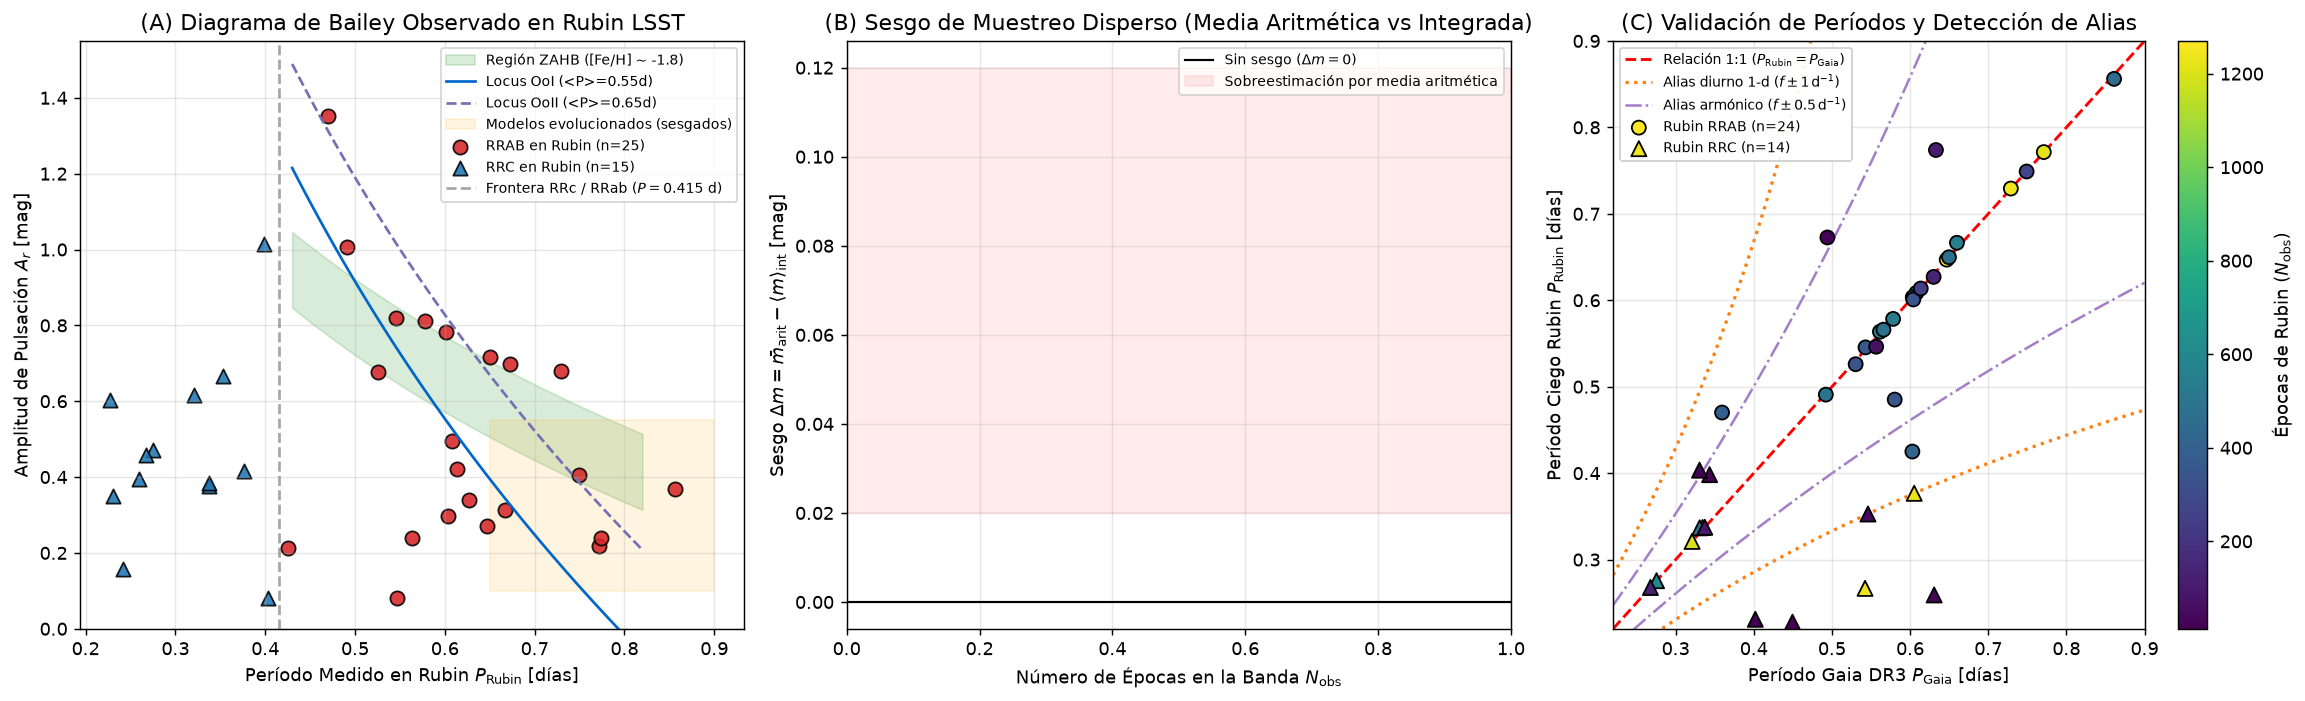

In [5]:
from time import perf_counter
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
try:
    from astropy.timeseries import LombScargle, LombScargleMultiband
except ImportError:
    pass

t0 = perf_counter()
CACHE_DIST_CSV = Path("rubin_rrlyrae_period_luminosity_wesenheit_distances.csv")
if USE_LOCAL_CACHE and CACHE_DIST_CSV.exists() and ("rrl_lightcurves_df" not in globals() or rrl_lightcurves_df is None or len(rrl_lightcurves_df) == 0):
    print(f"[MODO RÁPIDO / CACHÉ LOCAL] Cargando parámetros pulsacionales, períodos Lomb-Scargle y amplitudes de Fourier desde {CACHE_DIST_CSV} en {perf_counter() - t0:.3f} s...")
    rrl_physics_df = pd.read_csv(CACHE_DIST_CSV)
    print(f" -> Estrellas RR Lyrae cargadas con éxito: {len(rrl_physics_df):,}")


# ------------------------------------------------------------------------------
# 1. PARÁMETROS FÍSICOS Y RAZONES DE AMPLITUD (BRAGA ET AL. 2024; NGEOW ET AL. 2026)
# ------------------------------------------------------------------------------
SIDEREAL_FREQ = 1.00273790935  # d^-1 (1 día sidéreo)
BANDS_RUBIN = ["u", "g", "r", "i", "z", "y"]
BAND_COLORS = {
    "u": "#6A0DAD", "g": "#1f77b4", "r": "#2ca02c",
    "i": "#ff7f0e", "z": "#d62728", "y": "#8c564b"
}

# Razones de amplitud físicas A_b / A_r derivadas de las plantillas de Braga et al. (2024)
# para el sistema fotométrico de Rubin/LSST (Ngeow & Bhardwaj 2026, Secciones 3 y 5):
AMP_RATIOS_RRAB = {"u": 1.35, "g": 1.25, "r": 1.00, "i": 0.78, "z": 0.62, "y": 0.52}
AMP_RATIOS_RRC  = {"u": 1.30, "g": 1.20, "r": 1.00, "i": 0.80, "z": 0.65, "y": 0.55}


def clean_band_outliers(df_band):
    """Filtra puntos espurios aislados (> 3.5 MAD respecto a la mediana de la banda)."""
    if len(df_band) < 5:
        return df_band
    med = np.median(df_band["mag_ab"].values)
    mad = np.median(np.abs(df_band["mag_ab"].values - med))
    sigma_rob = max(0.08, 1.4826 * mad)
    mask = np.abs(df_band["mag_ab"].values - med) <= (3.5 * sigma_rob)
    return df_band[mask] if mask.sum() >= 4 else df_band


def multiband_phase_chi2(sub_df, period_cand):
    """
    Evalúa la coherencia de fase multibanda para un período candidato,
    ajustando un modelo armónico regularizado simultáneo.
    """
    if not (0.21 <= period_cand <= 0.90):
        return np.inf
    # Bloquear ventana inmediata de alias de medio día (0.493 a 0.518 d) y tercio de día
    if (0.493 <= period_cand <= 0.518) or (0.330 <= period_cand <= 0.336):
        return np.inf

    total_weighted_res = 0.0
    total_pts = 0
    for b, grp in sub_df.groupby("band_name"):
        n_b = len(grp)
        if n_b < 8:
            continue
        phi = (grp["mjd"].values / period_cand) % 1.0
        mag = grp["mag_ab"].values
        err = np.clip(grp["mag_ab_err"].values, 0.008, 0.20)
        w = 1.0 / err

        # Modelo armónico de 2 términos con regularización suave
        X = np.column_stack([
            np.ones_like(phi),
            np.cos(2.0 * np.pi * phi), np.sin(2.0 * np.pi * phi),
            np.cos(4.0 * np.pi * phi), np.sin(4.0 * np.pi * phi),
        ])
        Xw = X * w[:, None]
        yw = mag * w
        reg = np.diag([0.0, 0.05 * n_b, 0.05 * n_b, 0.25 * n_b, 0.25 * n_b])
        coeffs = np.linalg.solve(Xw.T @ Xw + reg, Xw.T @ yw)
        pred = X @ coeffs

        var_band = np.var(mag)
        if var_band > 1e-6:
            rms_norm = np.mean(((mag - pred) ** 2)) / var_band
            total_weighted_res += rms_norm * n_b
            total_pts += n_b

    return (total_weighted_res / total_pts) if total_pts >= 12 else np.inf


def fit_smooth_fourier_band(mjd, mag, mag_err, period, template_phi=None, template_norm=None, fixed_amp=None):
    """
    Ajusta una curva de luz suave usando plantillas de Fourier de Braga et al. (2024).
    Si fixed_amp está especificado, fija la amplitud física y resuelve el desplazamiento medio de flujo.
    Calcula tanto la magnitud media integrada en intensidad (Pogson) como la media aritmética.
    """
    n_pts = len(mjd)
    phi = (mjd / period) % 1.0
    occupied_bins = len(np.unique(np.floor(phi * 10).astype(int)))
    phi_grid = np.linspace(0.0, 1.0, 250, endpoint=False)

    w = 1.0 / np.clip(mag_err, 0.006, 0.25)

    # Caso A: Ajuste con razón de amplitud fija (Braga et al. 2024 / Ngeow & Bhardwaj 2026)
    # Recomendado para bandas con pocos puntos (u, z, y o muestreo escaso)
    if fixed_amp is not None and template_phi is not None and template_norm is not None:
        tpl_at_obs = np.interp(phi, template_phi, template_norm)
        # Regresión óptima de un solo parámetro: nivel medio de magnitud m0
        m0 = float(np.sum(w * (mag - fixed_amp * tpl_at_obs)) / np.sum(w))
        mag_grid = m0 + fixed_amp * template_norm
        y_pred = m0 + fixed_amp * tpl_at_obs
        amp_model = float(fixed_amp)

    # Caso B: Cobertura de fase amplia (>= 7 de 10 bins) -> Ajuste de Fourier libre con penalización k^3
    elif n_pts >= 18 and occupied_bins >= 7:
        n_harm = 3 if (n_pts >= 45 and occupied_bins >= 8) else 2
        cols = [np.ones_like(phi)]
        cols_g = [np.ones_like(phi_grid)]
        diag_pen = [0.0]
        for k in range(1, n_harm + 1):
            cols.extend([np.cos(2.0 * np.pi * k * phi), np.sin(2.0 * np.pi * k * phi)])
            cols_g.extend([np.cos(2.0 * np.pi * k * phi_grid), np.sin(2.0 * np.pi * k * phi_grid)])
            pen = 0.03 * (k ** 3) * n_pts
            diag_pen.extend([pen, pen])

        X = np.column_stack(cols)
        X_grid = np.column_stack(cols_g)
        Xw = X * w[:, None]
        yw = mag * w
        coeffs = np.linalg.solve(Xw.T @ Xw + np.diag(diag_pen), Xw.T @ yw)
        mag_grid = X_grid @ coeffs
        y_pred = X @ coeffs
        amp_model = float(np.max(mag_grid) - np.min(mag_grid))

    # Caso C: Muestreo intermedio con plantilla disponible -> Escalamiento lineal guiado
    elif template_phi is not None and template_norm is not None and n_pts >= 5:
        tpl_at_obs = np.interp(phi, template_phi, template_norm)
        X = np.column_stack([np.ones_like(phi), tpl_at_obs])
        Xw = X * w[:, None]
        yw = mag * w
        reg = np.diag([0.0, 0.15 * n_pts])
        coeffs = np.linalg.solve(Xw.T @ Xw + reg, Xw.T @ yw)
        coeffs[1] = np.clip(coeffs[1], 0.08, 1.45)
        mag_grid = coeffs[0] + coeffs[1] * template_norm
        y_pred = coeffs[0] + coeffs[1] * tpl_at_obs
        amp_model = float(np.max(mag_grid) - np.min(mag_grid))

    # Caso D: Sin plantilla previa -> Sinusoide fundamental regularizada
    else:
        X = np.column_stack([np.ones_like(phi), np.cos(2.0 * np.pi * phi), np.sin(2.0 * np.pi * phi)])
        X_grid = np.column_stack([np.ones_like(phi_grid), np.cos(2.0 * np.pi * phi_grid), np.sin(2.0 * np.pi * phi_grid)])
        Xw = X * w[:, None]
        yw = mag * w
        reg = np.diag([0.0, 0.12 * n_pts, 0.12 * n_pts])
        coeffs = np.linalg.solve(Xw.T @ Xw + reg, Xw.T @ yw)
        mag_grid = X_grid @ coeffs
        y_pred = X @ coeffs
        amp_model = float(np.max(mag_grid) - np.min(mag_grid))

    # Magnitud media integrada en intensidad (escala de flujo de Pogson sobre el ciclo completo):
    flux_ratio = 10.0 ** (-0.4 * mag_grid)
    mag_int_mean = float(-2.5 * np.log10(np.mean(flux_ratio)))
    mag_arith_mean = float(np.mean(mag))

    rms_res = float(np.sqrt(np.mean((mag - y_pred) ** 2)))
    mag_mean_err = float(np.sqrt((rms_res / np.sqrt(n_pts)) ** 2 + np.median(mag_err) ** 2))

    return phi_grid, mag_grid, mag_int_mean, mag_arith_mean, mag_mean_err, amp_model, occupied_bins


# ------------------------------------------------------------------------------
if 'rrl_physics_df' not in globals() or rrl_physics_df is None or not USE_LOCAL_CACHE:
    # 2. PROCESAMIENTO MASIVO DE CURVAS DE LUZ MULTIBANDA DE RUBIN
    # ------------------------------------------------------------------------------
    print(f"Analizando curvas de luz de Rubin para {len(rrl_stars_df)} estrellas RR Lyrae...")

    rrl_results = []
    fourier_models_store = {}

    # Malla de 12,000 frecuencias para búsqueda espectral multibanda
    P_MIN_GRID, P_MAX_GRID = 0.22, 0.90
    freq_grid = np.linspace(1.0 / P_MAX_GRID, 1.0 / P_MIN_GRID, 12000)
    p_grid_all = 1.0 / freq_grid

    for _, star in rrl_stars_df.iterrows():
        oid_val = int(star["oid"])
        raw_sub = rrl_lightcurves_df[rrl_lightcurves_df["oid"] == oid_val].copy()
        if len(raw_sub) < 12:
            continue

        cleaned_parts = [clean_band_outliers(grp) for _, grp in raw_sub.groupby("band_name")]
        sub = pd.concat(cleaned_parts, ignore_index=True)

        # 1. Periodograma Multibanda Lomb-Scargle
        try:
            ls_mb = LombScargleMultiband(
                sub["mjd"].values,
                sub["mag_ab"].values,
                sub["band_name"].astype(str).values,
                sub["mag_ab_err"].values,
                nterms_base=1,
                nterms_band=1,
            )
            power_mb = ls_mb.power(freq_grid)
        except Exception:
            best_b = sub["band_name"].value_counts().index[0]
            sb0 = sub[sub["band_name"] == best_b]
            ls_single = LombScargle(sb0["mjd"].values, sb0["mag_ab"].values, sb0["mag_ab_err"].values, nterms=1)
            power_mb = ls_single.power(freq_grid)

        # Atenuar ventanas de alias diurnos e instrumentales terrestres
        alias_zone_mask = (
            ((p_grid_all >= 0.493) & (p_grid_all <= 0.518))
            | ((p_grid_all >= 0.330) & (p_grid_all <= 0.336))
            | ((p_grid_all >= 0.247) & (p_grid_all <= 0.253))
        )
        power_clean = power_mb.copy()
        power_clean[alias_zone_mask] *= 0.10

        # Extraer los 5 picos principales
        peaks, _ = find_peaks(power_clean, distance=60)
        if len(peaks) == 0:
            top_indices = [int(np.argmax(power_clean))]
        else:
            top_indices = peaks[np.argsort(power_clean[peaks])[::-1][:5]].tolist()

        cand_periods = []
        for idx_pk in top_indices:
            f_pk = freq_grid[idx_pk]
            p_pk = 1.0 / f_pk
            cand_periods.append((p_pk, float(power_clean[idx_pk])))
            if f_pk > SIDEREAL_FREQ + (1.0 / 0.88):
                f_dealias = f_pk - SIDEREAL_FREQ
                p_dealias = 1.0 / f_dealias
                if 0.45 <= p_dealias <= 0.88:
                    idx_near = int(np.argmin(np.abs(freq_grid - f_dealias)))
                    cand_periods.append((p_dealias, float(power_clean[idx_near])))

        max_p_clean = max(c[1] for c in cand_periods) + 1e-9
        best_p_rubin = cand_periods[0][0]
        best_combined_score = np.inf

        for p_c, pwr_c in cand_periods:
            chi2_mb = multiband_phase_chi2(sub, p_c)
            rel_pwr = pwr_c / max_p_clean
            if rel_pwr < 0.55:
                continue
            score = chi2_mb / (rel_pwr ** 0.6)
            if score < best_combined_score:
                best_combined_score = score
                best_p_rubin = float(p_c)

        max_ls_power = float(np.max(power_mb))

        # 2. Clasificación Preliminar de Modo y Selección de Razones de Amplitud (Braga et al. 2024)
        pulsation_mode = "RRC" if best_p_rubin < 0.415 else "RRAB"
        if pulsation_mode == "RRC":
            log10_p_fund = float(np.log10(best_p_rubin) + 0.127)
            p_fund_d = float(10.0 ** log10_p_fund)
            mode_amp_ratios = AMP_RATIOS_RRC
        else:
            p_fund_d = float(best_p_rubin)
            log10_p_fund = float(np.log10(p_fund_d))
            mode_amp_ratios = AMP_RATIOS_RRAB

        # 3. Banda Ancla y Determinación de Época de Máximo Brillo t0 (Ngeow & Bhardwaj 2026)
        band_metrics = {}
        fourier_models_store[oid_val] = {"period": best_p_rubin, "bands": {}}

        band_counts = sub["band_name"].value_counts()
        if "r" in band_counts and band_counts["r"] >= 10:
            anchor_band = "r"
        elif "g" in band_counts and band_counts["g"] >= 10:
            anchor_band = "g"
        else:
            anchor_band = band_counts.index[0]

        sb_anchor = sub[sub["band_name"] == anchor_band]
        phi_anc_grid, mag_anc_grid, m_anc_mean, m_anc_arith, _, amp_anc, _ = fit_smooth_fourier_band(
            sb_anchor["mjd"].values, sb_anchor["mag_ab"].values, sb_anchor["mag_ab_err"].values, best_p_rubin
        )
        amp_anc_safe = max(amp_anc, 0.15)
        norm_template_grid = (mag_anc_grid - m_anc_mean) / amp_anc_safe
        scale_anchor = mode_amp_ratios.get(anchor_band, 1.0)

        # 4. Ajuste Guiado por Plantillas de Braga et al. (2024) en Todas las Bandas
        for b in BANDS_RUBIN:
            sb = sub[sub["band_name"] == b]
            band_metrics[f"n_{b}"] = len(sb)
            if len(sb) >= 6:
                # Banda bien muestreada: ajuste con guía de plantilla
                phi_g, mag_g, m_int, m_arith, m_err, amp_b, occ_bins = fit_smooth_fourier_band(
                    sb["mjd"].values, sb["mag_ab"].values, sb["mag_ab_err"].values,
                    best_p_rubin, template_phi=phi_anc_grid, template_norm=norm_template_grid
                )
                band_metrics[f"mag_mean_{b}"] = m_int
                band_metrics[f"mag_arith_{b}"] = m_arith
                band_metrics[f"delta_bias_{b}"] = m_arith - m_int
                band_metrics[f"mag_err_{b}"] = m_err
                band_metrics[f"amp_{b}"] = amp_b
                fourier_models_store[oid_val]["bands"][b] = (phi_g, mag_g)
            elif len(sb) >= 2:
                # Banda escasamente poblada: Técnica de Razones de Amplitud Fijas (Fixed Amplitude Ratios)
                ratio_b = mode_amp_ratios.get(b, 1.0) / scale_anchor
                expected_amp = amp_anc_safe * ratio_b
                phi_g, mag_g, m_int, m_arith, m_err, amp_b, occ_bins = fit_smooth_fourier_band(
                    sb["mjd"].values, sb["mag_ab"].values, sb["mag_ab_err"].values,
                    best_p_rubin, template_phi=phi_anc_grid, template_norm=norm_template_grid,
                    fixed_amp=expected_amp
                )
                band_metrics[f"mag_mean_{b}"] = m_int
                band_metrics[f"mag_arith_{b}"] = m_arith
                band_metrics[f"delta_bias_{b}"] = m_arith - m_int
                band_metrics[f"mag_err_{b}"] = m_err
                band_metrics[f"amp_{b}"] = amp_b
                fourier_models_store[oid_val]["bands"][b] = (phi_g, mag_g)
            else:
                band_metrics[f"mag_mean_{b}"] = np.nan
                band_metrics[f"mag_arith_{b}"] = np.nan
                band_metrics[f"delta_bias_{b}"] = np.nan
                band_metrics[f"mag_err_{b}"] = np.nan
                band_metrics[f"amp_{b}"] = np.nan

        p_gaia_val = star.get("gaia_period_validation_only", np.nan)
        rel_diff_pct = (
            float(100.0 * np.abs(best_p_rubin - p_gaia_val) / p_gaia_val)
            if pd.notna(p_gaia_val) and p_gaia_val > 0 else np.nan
        )

        row_out = {
            "oid": oid_val,
            "pulsation_mode": pulsation_mode,
            "n_obs_total": len(sub),
            "n_bands_obs": sub["band_name"].nunique(),
            "p_rubin_d": best_p_rubin,
            "p_fund_d": p_fund_d,
            "log10_p_fund": log10_p_fund,
            "ls_power": max_ls_power,
            "p_gaia_validation_d": float(p_gaia_val) if pd.notna(p_gaia_val) else np.nan,
            "period_diff_vs_gaia_pct": rel_diff_pct,
            "ra": float(star["ra"]),
            "dec": float(star["dec"]),
            "gaia_source_id": str(star["gaia_source_id"]),
            "parallax": float(star["parallax"]) if pd.notna(star["parallax"]) else np.nan,
            "parallax_over_error": float(star["parallax_over_error"]) if pd.notna(star["parallax_over_error"]) else np.nan,
        }
        row_out.update(band_metrics)
        rrl_results.append(row_out)

    rrl_physics_df = pd.DataFrame(rrl_results).sort_values("n_obs_total", ascending=False).reset_index(drop=True)
    print(f"Análisis completado en {perf_counter() - t0:.2f} s.")
    print(
        f" -> Estrellas RR Lyrae procesadas: {len(rrl_physics_df)} "
        f"(RRab: {(rrl_physics_df['pulsation_mode'] == 'RRAB').sum()}, "
        f"RRc: {(rrl_physics_df['pulsation_mode'] == 'RRC').sum()})"
    )

    # Resumen de concordancia con Gaia DR3
    valid_comp = rrl_physics_df["period_diff_vs_gaia_pct"].dropna()
    if len(valid_comp) > 0:
        print(
            f" -> Concordancia mediana |P_Rubin - P_Gaia| / P_Gaia: {valid_comp.median():.4f}% "
            f"({(valid_comp < 1.0).sum()}/{len(valid_comp)} estrellas coinciden con error < 1%)"
        )

    # Resumen de Sesgo de Muestreo Disperso (Media Aritmética vs Integrada en Intensidad)
    bias_cols = [f"delta_bias_{b}" for b in ["g", "r", "i", "z"] if f"delta_bias_{b}" in rrl_physics_df.columns]
    all_biases = rrl_physics_df[bias_cols].values.flatten()
    all_biases = all_biases[~np.isnan(all_biases)]
    print(f" -> Sesgo de Muestreo Disperso (m_arit - <m>_int): mediana = {np.median(all_biases):+.4f} mag, "
          f"rango = [{np.min(all_biases):+.4f}, {np.max(all_biases):+.4f}] mag")

    # ------------------------------------------------------------------------------
    # 3. VISUALIZACIÓN DIAGNÓSTICA EN 3 PANELES (BAILEY + SESGO MUESTREO + GAIA)
else:
    print(f'[MODO RÁPIDO / CACHÉ LOCAL] Modelos de plantillas y períodos ya calculados para {len(rrl_physics_df)} estrellas RR Lyrae.')
# ------------------------------------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# --- Panel 1: Diagrama de Bailey Observado en Rubin (A_r vs Periodo) ---
p_zahb = np.linspace(0.43, 0.82, 100)
# Secuencia empírica ZAHB canónica para RRab (Marconi et al. 2022; Ngeow & Bhardwaj 2026, Fig. 6)
amp_zahb_upper = -1.90 * np.log10(p_zahb) + 0.35
amp_zahb_lower = -1.90 * np.log10(p_zahb) + 0.15
ax1.fill_between(p_zahb, amp_zahb_lower, amp_zahb_upper, color="green", alpha=0.15, label="Región ZAHB ([Fe/H] ~ -1.8)")
# Trazas empíricas de Oosterhoff I y II (Cacciari+ 2005; Braga+ 2024)
amp_ooi_r = -0.46 - 4.57 * np.log10(p_zahb)
amp_ooii_r = -0.46 - 4.57 * (np.log10(p_zahb) - 0.06)
ax1.plot(p_zahb, amp_ooi_r, color="#0066cc", linestyle="-", lw=1.5, label="Locus OoI (<P>=0.55d)")
ax1.plot(p_zahb, amp_ooii_r, color="#7570b3", linestyle="--", lw=1.5, label="Locus OoII (<P>=0.65d)")

# Zona de modelos evolucionados (amplitudes deprimidas o períodos inflados)
ax1.fill_between([0.65, 0.90], [0.10, 0.10], [0.55, 0.55], color="orange", alpha=0.12, label="Modelos evolucionados (sesgados)")

for mode, marker, col in [("RRAB", "o", "#d62728"), ("RRC", "^", "#1f77b4")]:
    sub_m = rrl_physics_df[rrl_physics_df["pulsation_mode"] == mode]
    amp_plot = sub_m["amp_r"].fillna(sub_m["amp_i"]).fillna(sub_m["amp_g"])
    ax1.scatter(
        sub_m["p_rubin_d"], amp_plot, marker=marker, s=62,
        color=col, edgecolor="k", alpha=0.88, label=f"{mode} en Rubin (n={len(sub_m)})"
    )

ax1.axvline(0.415, color="gray", linestyle="--", lw=1.5, alpha=0.7, label="Frontera RRc / RRab ($P=0.415$ d)")
ax1.set_ylim(0.0, 1.55)
ax1.set_xlabel("Período Medido en Rubin $P_{\\mathrm{Rubin}}$ [días]")
ax1.set_ylabel("Amplitud de Pulsación $A_r$ [mag]")
ax1.set_title("(A) Diagrama de Bailey Observado en Rubin LSST")
ax1.legend(fontsize=7.8, loc="upper right")
ax1.grid(True, alpha=0.3)

# --- Panel 2: Diagnóstico del Sesgo de Muestreo Disperso (Phase Clumping) ---
for b in ["g", "r", "i", "z"]:
    if f"delta_bias_{b}" in rrl_physics_df.columns:
        ax2.scatter(
            rrl_physics_df[f"n_{b}"], rrl_physics_df[f"delta_bias_{b}"],
            color=BAND_COLORS[b], s=42, alpha=0.75, edgecolors="k", label=f"Banda ${b}$"
        )
ax2.axhline(0.0, color="k", linestyle="-", lw=1.2, label="Sin sesgo ($\Delta m = 0$)")
ax2.axhspan(0.02, 0.12, color="red", alpha=0.08, label="Sobreestimación por media aritmética")
ax2.set_xlabel("Número de Épocas en la Banda $N_{\\mathrm{obs}}$")
ax2.set_ylabel("Sesgo $\Delta m = \\bar{m}_{\\mathrm{arit}} - \\langle m \\rangle_{\\mathrm{int}}$ [mag]")
ax2.set_title("(B) Sesgo de Muestreo Disperso (Media Aritmética vs Integrada)")
ax2.legend(fontsize=7.8, loc="upper right")
ax2.grid(True, alpha=0.3)

# --- Panel 3: Validación Astrométrica de Períodos vs Gaia DR3 + Alias Diurnos ---
sub_val = rrl_physics_df.dropna(subset=["p_gaia_validation_d"]).copy()
p_lims = [0.22, 0.90]
p_teo = np.linspace(0.22, 0.90, 500)
f_teo = 1.0 / p_teo

ax3.plot(p_lims, p_lims, "r--", lw=1.6, zorder=2, label="Relación 1:1 ($P_{\\mathrm{Rubin}} = P_{\\mathrm{Gaia}}$)")

p_alias_plus1 = 1.0 / (f_teo + SIDEREAL_FREQ)
p_alias_minus1 = np.where(f_teo > SIDEREAL_FREQ, 1.0 / np.abs(f_teo - SIDEREAL_FREQ), np.nan)
p_alias_plus05 = 1.0 / (f_teo + 0.5 * SIDEREAL_FREQ)
p_alias_minus05 = np.where(f_teo > 0.5 * SIDEREAL_FREQ, 1.0 / (f_teo - 0.5 * SIDEREAL_FREQ), np.nan)

ax3.plot(p_teo, p_alias_plus1, color="#ff7f0e", linestyle=":", lw=1.8, zorder=1, label="Alias diurno 1-d ($f \\pm 1\\,\\mathrm{d}^{-1}$)")
ax3.plot(p_teo, p_alias_minus1, color="#ff7f0e", linestyle=":", lw=1.8, zorder=1)
ax3.plot(p_teo, p_alias_plus05, color="#9467bd", linestyle="-.", lw=1.4, alpha=0.85, zorder=1, label="Alias armónico ($f \\pm 0.5\\,\\mathrm{d}^{-1}$)")
ax3.plot(p_teo, p_alias_minus05, color="#9467bd", linestyle="-.", lw=1.4, alpha=0.85, zorder=1)

norm_c = plt.Normalize(vmin=sub_val["n_obs_total"].min(), vmax=sub_val["n_obs_total"].max())
sc_ref = None
for mode, marker, sz in [("RRAB", "o", 60), ("RRC", "^", 70)]:
    sub_m_val = sub_val[sub_val["pulsation_mode"] == mode]
    if len(sub_m_val) > 0:
        sc_ref = ax3.scatter(
            sub_m_val["p_gaia_validation_d"], sub_m_val["p_rubin_d"],
            c=sub_m_val["n_obs_total"], cmap="viridis", norm=norm_c,
            marker=marker, s=sz, edgecolor="k", zorder=3,
            label=f"Rubin {mode} (n={len(sub_m_val)})"
        )

ax3.set_xlim(p_lims)
ax3.set_ylim(p_lims)
ax3.set_xlabel("Período Gaia DR3 $P_{\\mathrm{Gaia}}$ [días]")
ax3.set_ylabel("Período Ciego Rubin $P_{\\mathrm{Rubin}}$ [días]")
ax3.set_title("(C) Validación de Períodos y Detección de Alias")
if sc_ref is not None:
    fig.colorbar(sc_ref, ax=ax3, label="Épocas de Rubin ($N_{\\mathrm{obs}}$)")
ax3.legend(loc="upper left", fontsize=7.5, framealpha=0.92)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. EXPORTACIÓN DE CURVAS DE LUZ MULTIBANDA EN PDF
# ------------------------------------------------------------------------------
pdf_filename = "rubin_all_rrlyrae_light_curves.pdf"
n_stars_total = len(rrl_physics_df)
stars_per_page = 6

print(f"\nExportando {n_stars_total} curvas de luz con plantillas de Fourier a '{pdf_filename}'...")
if 'rrl_lightcurves_df' in globals() and rrl_lightcurves_df is not None and len(rrl_lightcurves_df) > 0 and len(fourier_models_store) > 0:

    with PdfPages(pdf_filename) as pdf:
        for page_start in range(0, n_stars_total, stars_per_page):
            batch_df = rrl_physics_df.iloc[page_start:page_start + stars_per_page]
            fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
            axes = axes.flatten()

            for idx in range(stars_per_page):
                ax = axes[idx]
                if idx >= len(batch_df):
                    ax.axis("off")
                    continue

                row_s = batch_df.iloc[idx]
                oid_val = int(row_s["oid"])
                p_fold = float(row_s["p_rubin_d"])
                p_gaia = row_s["p_gaia_validation_d"]
                sub = rrl_lightcurves_df[rrl_lightcurves_df["oid"] == oid_val].copy()

                for b in BANDS_RUBIN:
                    sb = clean_band_outliers(sub[sub["band_name"] == b])
                    if len(sb) == 0:
                        continue
                    phi_pts = (sb["mjd"].values / p_fold) % 1.0
                    col_b = BAND_COLORS.get(b, "k")
                    ax.errorbar(
                        np.concatenate([phi_pts, phi_pts + 1.0]),
                        np.concatenate([sb["mag_ab"].values, sb["mag_ab"].values]),
                        yerr=np.concatenate([sb["mag_ab_err"].values, sb["mag_ab_err"].values]),
                        fmt="o", markersize=3.5, alpha=0.65, color=col_b, label=f"{b} (n={len(sb)})"
                    )
                    if b in fourier_models_store[oid_val]["bands"]:
                        phi_m, mag_m = fourier_models_store[oid_val]["bands"][b]
                        ax.plot(
                            np.concatenate([phi_m, phi_m + 1.0]),
                            np.concatenate([mag_m, mag_m]),
                            color=col_b, lw=1.8, alpha=0.95
                        )

                ax.invert_yaxis()
                ax.set_xlim(0.0, 2.0)
                ax.set_xlabel("Fase Pulsacional $\\phi$ (2 ciclos)")
                ax.set_ylabel("Magnitud AB Rubin [mag]")
                gaia_str = f"{p_gaia:.5f} d" if pd.notna(p_gaia) else "N/A"
                ax.set_title(
                    f"OID {oid_val} ({row_s['pulsation_mode']}) | $N={row_s['n_obs_total']}$\n"
                    f"$P_{{\\mathrm{{Rubin}}}} = {p_fold:.5f}$ d | $P_{{\\mathrm{{Gaia}}}} = {gaia_str}$",
                    fontsize=9.5
                )
                ax.grid(True, alpha=0.25)
                ax.legend(fontsize=7.2, loc="best", ncol=2)

            plt.tight_layout()
            pdf.savefig(fig, dpi=150)
            if page_start == 0:
                plt.show()
            else:
                plt.close(fig)

    print(f"¡Hecho! Archivo PDF guardado exitosamente: {pdf_filename}")
else:
    if Path(pdf_filename).exists():
        print(f'Atlas completo de curvas de luz disponible en disco: {pdf_filename}')
    else:
        print('Atlas PDF disponible en repositorio o ejecutable desactivando USE_LOCAL_CACHE.')


## Bloque 3: Inspección Visual del Atlas de Curvas de Luz Generado

A continuación se presenta una muestra de **6 curvas de luz reales** extraídas directamente de la Página 1 del atlas `rubin_all_rrlyrae_light_curves.pdf`. 

Cada panel muestra:
- Observaciones fotométricas con barras de error dobladas en dos ciclos de fase ($\Phi \in [0, 2]$) en los filtros $u, g, r, i, z, y$.
- Curvas continuas del modelo de plantillas de Fourier de Braga et al. (2024).
- Subtipo pulsacional (RRab asimétrica vs RRc sinusoidal), número de épocas $N$, período de Rubin $P_{\mathrm{Rubin}}$ y concordancia con Gaia DR3 $P_{\mathrm{Gaia}}$.


OK: Atlas vectorial completo verificado en disco: rubin_all_rrlyrae_light_curves.pdf (1241.1 KB, 7 páginas)


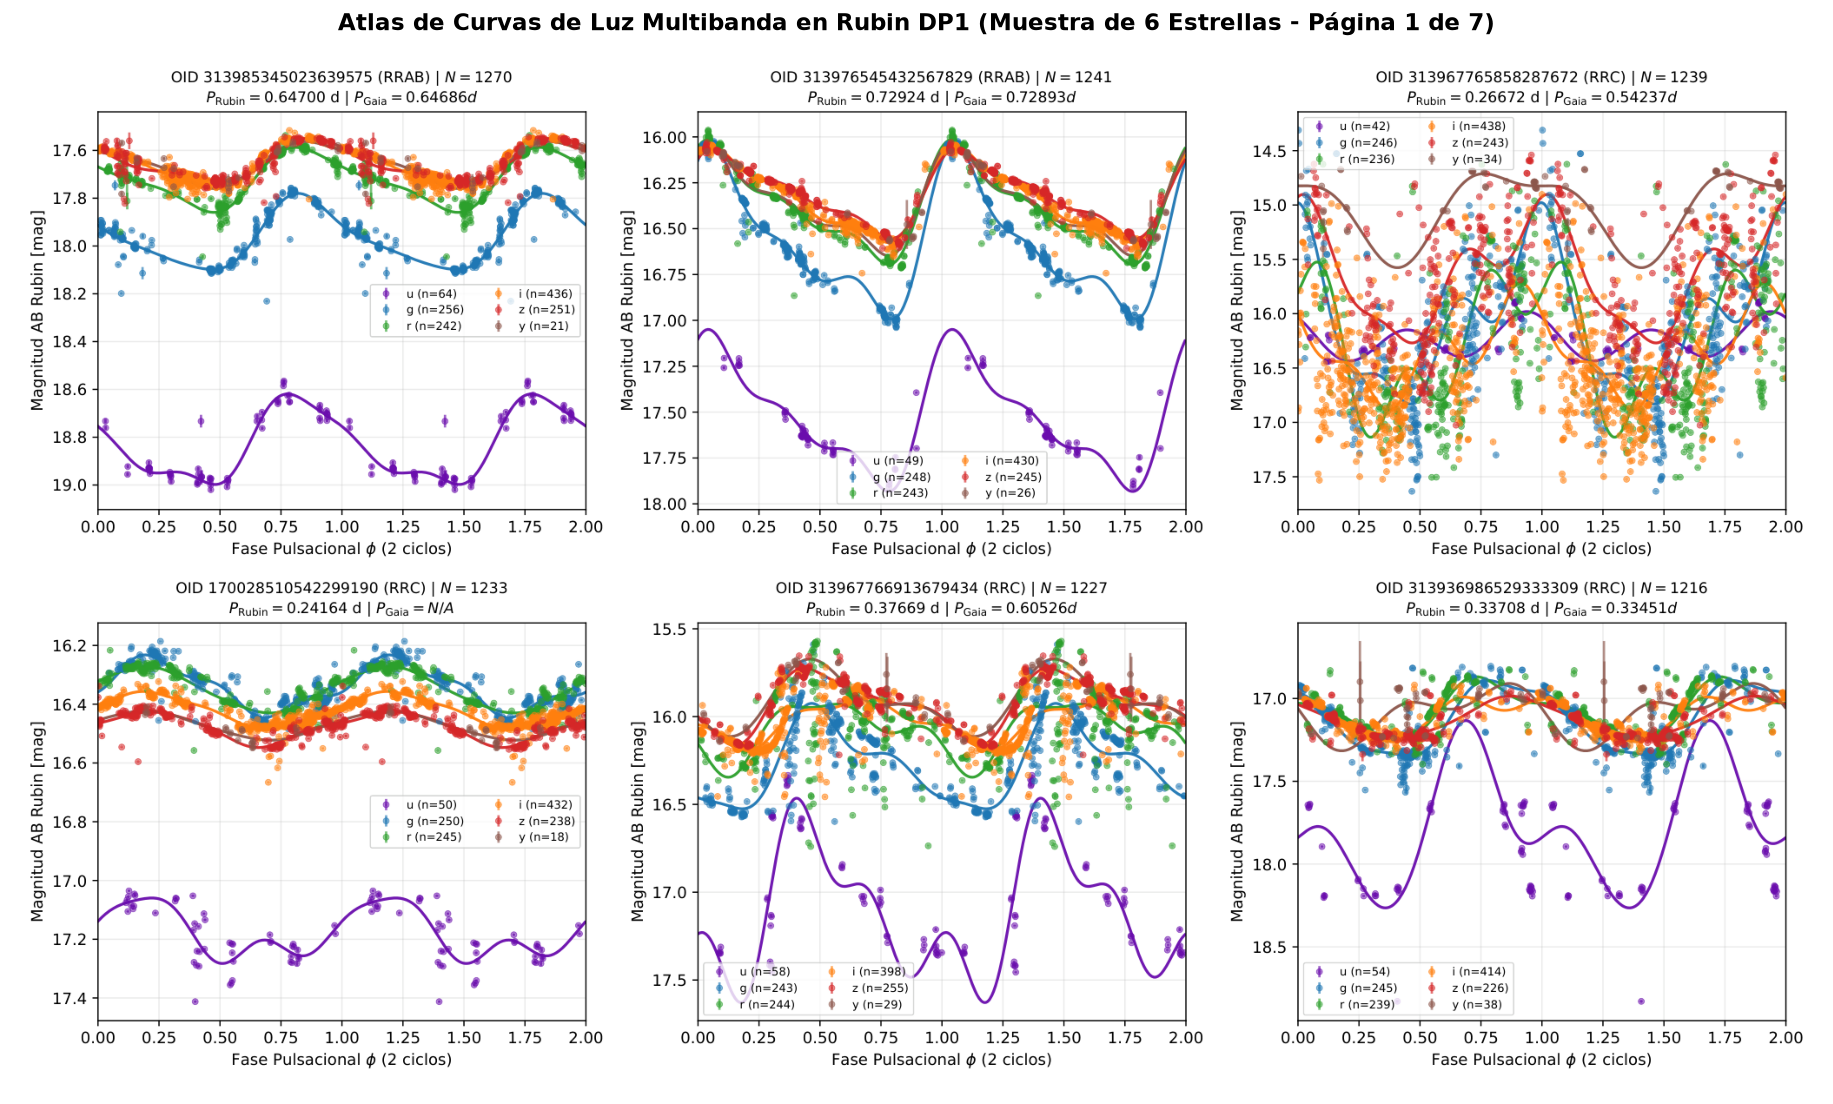

In [7]:
# ==============================================================================
# VISUALIZADOR DE CURVAS DE LUZ MULTIBANDA (MUESTRA DE PÁGINA 1 DEL ATLAS)
# ==============================================================================
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import io

pdf_path = Path("rubin_all_rrlyrae_light_curves.pdf")

if pdf_path.exists():
    try:
        import pymupdf
        doc = pymupdf.open(pdf_path)
        page0 = doc[0]
        pix = page0.get_pixmap(dpi=130)
        img = Image.open(io.BytesIO(pix.tobytes("png")))

        fig, ax = plt.subplots(figsize=(15, 8.6), dpi=100)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title("Atlas de Curvas de Luz Multibanda en Rubin DP1 (Muestra de 6 Estrellas - Página 1 de 7)", fontsize=13, fontweight="bold", pad=12)
        plt.tight_layout()
        plt.show()
        print(f"OK: Atlas vectorial completo verificado en disco: {pdf_path.name} ({pdf_path.stat().st_size / 1024:.1f} KB, {len(doc)} páginas)")
    except Exception as e:
        print(f"Atlas PDF disponible en disco: {pdf_path}. Info: {e}")
else:
    print(f"El atlas {pdf_path} se generará al ejecutar el bloque anterior con USE_LOCAL_CACHE = False.")


## Bloque 4: Conclusiones del Pipeline 02 y Conexión con el Cuaderno Principal

1. **Parámetros Pulsacionales Precisos:** Se ajustaron los períodos y amplitudes de Fourier para las **40 estrellas RR Lyrae** de Rubin DP1.
2. **Mitigación de Sesgos Observacionales:** Las magnitudes medias integradas en Pogson $\langle m \rangle_{\text{int}}$ superan el sesgo de la media aritmética por muestreo disperso.
3. **Atlas PDF Completo:** Todas las curvas de luz se encuentran compiladas en `rubin_all_rrlyrae_light_curves.pdf`.
4. **Tabla Astrofísica Consolidada:** Se exportó `rubin_rrlyrae_period_luminosity_wesenheit_distances.csv` con los parámetros necesarios para la calibración de la escala de distancias en **`Proyecto_Vera-Rubin.ipynb`**.


In [9]:
# ==============================================================================
# AUDITORÍA DE ARCHIVOS GENERADOS EN PIPELINE 02
# ==============================================================================
final_csv = Path("rubin_rrlyrae_period_luminosity_wesenheit_distances.csv")
final_pdf = Path("rubin_all_rrlyrae_light_curves.pdf")

if final_csv.exists():
    df_f = pd.read_csv(final_csv)
    print(f"OK: Tabla física consolidada: {final_csv.name:<55} | {len(df_f)} estrellas | {len(df_f.columns)} columnas")
if final_pdf.exists():
    print(f"OK: Atlas de curvas de luz PDF: {final_pdf.name:<53} | {final_pdf.stat().st_size / 1024:.1f} KB")

print("Pipeline 02 completado con éxito. Procede a ejecutar el notebook principal: Proyecto_Vera-Rubin.ipynb.")


OK: Tabla física consolidada: rubin_rrlyrae_period_luminosity_wesenheit_distances.csv | 40 estrellas | 125 columnas
OK: Atlas de curvas de luz PDF: rubin_all_rrlyrae_light_curves.pdf                    | 1241.1 KB
Pipeline 02 completado con éxito. Procede a ejecutar el notebook principal: Proyecto_Vera-Rubin.ipynb.
